# GROUP ASSIGNMENT 1
## COURSE: AERO 473 AIRCRAFT VEHICLE DESIGN
## GROUP 7
--------------------
* Kobina Amo Adu
* Frimpong Isaac
* Thompson Daniel
* Ferdinand Ferguson Alexander Hope
* Mensah Dumfeh Rudolf
* Dumasi Joshua Tawiah Iddi
* Techie Derrick Joseph
* Quayson Christian Nkrumah
* Quansah Emmanuel
* Jones Ato

# Problem definition
The mini coding project required we determine the take-off weight of an antisubmarine aircraft as computed in Aircraft Design Concept by Raymer.
However, in our work we made use of python programming to calculate the take-off weight using the weight fraction, fuel fraction and an initial empty weight guess.

Mathematically;

$W0=(Wcrew+Wpayload)/(1-(1+allowance)(1-W7/W0)-0.93 W0_g^-0.07)$

where:
* $W7/W0$ is the product of the weight fraction across the flight profile.
* $W0_g$ is the educated guess value that will be iterated to approximate take-off weight of the aircraft. Error margin, $10^-4$

Our tasked goes further to probe the trade-off made when the payload is varied accross a range of cruise range. Similarly, we varied the cruise range across a range of values to explore the take-off weight trade offs we could make.

Reference the textbook for all constants assumptions and proof of formulae.

Aircraft Design: A Conceptal Approah by Daniel P. Raymer, Second Edition, pg 26 - 31

## Importing relevant python library for the project

In [10]:
from math import exp              # exponenet function, e
import matplotlib.pyplot as plt   # plotting library

## Defining relevant constants

In [11]:
global C_cruise, C_loiter, V, L_D_cruise, L_D_loiter, W_crew, fuel_allowance
C_cruise = 0.0001389   # specific fuel consumption at cruise, 1/s
V = 569                # Aircraft velocity at cruise, ft/s
L_D_cruise = 13.9      # Life-to-drag ratio during cruise
L_D_loiter = 16        # lift-to-drag ratio during loiter
E_l1 = 10800           # Endurance time for loiter 3 - 4, s
C_loiter = 0.0001111   # specific fuel consumption during loiter, 1/s
E_l2 = 1200            # endurance time for loiter at 5 - 6, s
W_crew = 800           # Weight of crew, lb
W1_W0 = 0.97           # Weight fraction during warm-up and take-off, W1/W0
W2_W1 = 0.985          # Weight fraction during climb, W2/W1
W7_W6 = 0.995          # Weight fraction during landing, W7/W6

# Other constants such as fuel allowance = 6%, A = 0.93, c = -0.07 and Kvc = 1.0 are quoted directly into the formulae when needed


## Defining relevant functions
1. Range formula:

$Wi/Wi-1=exp(-(RC)/V(L/D))$  ---------------------------------------- eqn 3.6 pg 17

2. Endurance formula:

$Wi/Wi-1=exp(-(E C)/(L/D))$  ---------------------------------------- eqn 3.8 pg 17

3. Take-off weight formula:

$W0=(Wcrew+Wpayload)/(1-(1+allowance)(1-W7/W0)-0.93 W0_g^-0.07)$ ---- eqn 3.4 pg 12

In [12]:
# Function to calculating the weight fraction at cruise using the range equation
def cruise_func(R):
    return exp( -(R*C_cruise) / (L_D_cruise*V) )

In [13]:
# Function to calculating the weight fraction during loiter using the endurance equation
def loiter_func(E):
    return exp( -(E*C_loiter) / L_D_loiter)

In [14]:
# Function to calculate the take-off weight
def take_off_weight_func(W0_guess, payload, W7_W0):
    # Calculating the estimated take-off weight
    W0 = (W_crew + payload) / (1 - 1.06*(1 - W7_W0) - 0.93*W0_guess**-0.07 )

    # Calculating the absolute difference between the estimated take-off weight and the guessed take-off weight
    err = abs(W0 - W0_guess)

    # logically test to terminate recursion or continue.
    if err <= 10**-4:
        return W0
    else:
        # Taking the average
        Avg_W0 = (W0 + W0_guess)/2
        # recuring computation of the take-off weight
        return take_off_weight_func(Avg_W0, payload, W7_W0)
    

## Taking inputs from the user.
Our computer programme computes the various take-off weight over a given range of cruise range values or range of payload values.
Types of inputs expected
1. range(start, end, step)
2. integer
3. float

In [15]:
R = eval( input("Enter your cruise range (start, end, step): ") )  # ---- Accepting inputs for range of values
W_payload = eval( input("Enter your payload (start, end, step): ") )  # --- Accepting inputs for payload values

# Converting int and floats into list for future iterations.
if type(R) in [int, float]: R = [R]
if type(W_payload) in [int, float]: W_payload = [W_payload]

# Displaying inputs
print(f"Range value(s): {R}", f"Payload value(s): {W_payload}", sep="\n")

Range value(s): [9114000]
Payload value(s): range(10000, 30000, 500)


## Calculating take-off weight, W0 and storing the data.

In [16]:
# Defining my x, y and z values as range, payload and take-off weight
x, y, z = ([], [], [])

# Varying the take-off weight with respect to a range of cruise range values.
for r in R:
    # calculating the weight fraction accross the entire mission profile.
    W7_W0 = W1_W0 * W2_W1 * cruise_func(r) * loiter_func(E_l1) * cruise_func(r) * loiter_func(E_l2) * W7_W6

    # Varying the take-off weight with respect to a range of payload values.
    for payload in W_payload:
        # Guessing the initial weight
        W0_guess = 50000 # 4 * (payload + W_crew)

        # Calculating W0
        W0 = take_off_weight_func(W0_guess, payload, W7_W0)

        # Saving the data in text files.
        x.append(r); y.append(payload); z.append(round(W0, 2))


## Displaying sample of the data computed

In [17]:
print("Range  Payload   Weight")
for i in range(len(z)):
    print(f"{x[i]:2d} {y[i]:2d} {z[i]:2.2f}")

Range  Payload   Weight
9114000 10000 59258.38
9114000 10500 61606.19
9114000 11000 63942.33
9114000 11500 66267.41
9114000 12000 68582.01
9114000 12500 70886.62
9114000 13000 73181.73
9114000 13500 75467.75
9114000 14000 77745.09
9114000 14500 80014.11
9114000 15000 82275.16
9114000 15500 84528.53
9114000 16000 86774.53
9114000 16500 89013.44
9114000 17000 91245.50
9114000 17500 93470.95
9114000 18000 95690.02
9114000 18500 97902.92
9114000 19000 100109.85
9114000 19500 102310.99
9114000 20000 104506.53
9114000 20500 106696.63
9114000 21000 108881.44
9114000 21500 111061.12
9114000 22000 113235.81
9114000 22500 115405.65
9114000 23000 117570.76
9114000 23500 119731.27
9114000 24000 121887.30
9114000 24500 124038.95
9114000 25000 126186.33
9114000 25500 128329.56
9114000 26000 130468.71
9114000 26500 132603.89
9114000 27000 134735.20
9114000 27500 136862.70
9114000 28000 138986.49
9114000 28500 141106.65
9114000 29000 143223.25
9114000 29500 145336.37


# Visualization of data computed

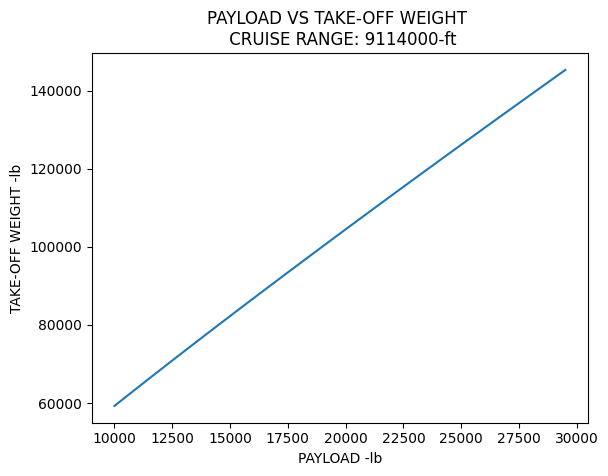

In [18]:
%matplotlib inline

# Making decision on what to plot
if len(x) + len(y) == 2:
    print(z)
    # print out the take-off weight if a single input was made for the range and payload.

elif x[0] == x[-1]:
    # Display a graph of payload vs take-off weight since the range is constant.
    plt.plot(y, z)
    plt.title(f"PAYLOAD VS TAKE-OFF WEIGHT \n CRUISE RANGE: {x[0]}-ft") # we plot y and z
    plt.xlabel("PAYLOAD -lb")
    plt.ylabel("TAKE-OFF WEIGHT -lb")

elif y[0] == y[-1]:
    # Display a graph of range vs take-off weight since the payload is constant.
    plt.plot(x, z)
    plt.title(f"RANGE VS TAKE-OFF WEIGHT \n PAYLOAD OF {y[0]}-lb")
    plt.xlabel("RANGE -ft")
    plt.ylabel("TAKE-OFF WEIGHT -lb")

plt.show()